In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [ ]:
df = pd.read_csv("/content/Dry_Bean_Dataset.csv")

##1. Data exploration

In [ ]:
df.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [ ]:
df.shape

(13611, 17)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  object 
dtypes: float64(1

In [ ]:
df.describe()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000
mean,53048.284549,855.283459,320.141867,202.270714,1.583242,0.750895,53768.200206,253.064220,0.749733,0.987143,0.873282,0.799864,0.006564,0.001716,0.643590,0.995063
std,29324.095717,214.289696,85.694186,44.970091,0.246678,0.092002,29774.915817,59.177120,0.049086,0.004660,0.059520,0.061713,0.001128,0.000596,0.098996,0.004366
min,20420.000000,524.736000,183.601165,122.512653,1.024868,0.218951,20684.000000,161.243764,0.555315,0.919246,0.489618,0.640577,0.002778,0.000564,0.410339,0.947687
25%,36328.000000,703.523500,253.303633,175.848170,1.432307,0.715928,36714.500000,215.068003,0.718634,0.985670,0.832096,0.762469,0.005900,0.001154,0.581359,0.993703
50%,44652.000000,794.941000,296.883367,192.431733,1.551124,0.764441,45178.000000,238.438026,0.759859,0.988283,0.883157,0.801277,0.006645,0.001694,0.642044,0.996386
75%,61332.000000,977.213000,376.495012,217.031741,1.707109,0.810466,62294.000000,279.446467,0.786851,0.990013,0.916869,0.834270,0.007271,0.002170,0.696006,0.997883
max,254616.000000,1985.370000,738.860154,460.198497,2.430306,0.911423,263261.000000,569.374358,0.866195,0.994677,0.990685,0.987303,0.010451,0.003665,0.974767,0.999733


###	Choose 5 features.

In [ ]:
df.drop(columns="Class").corr()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
Area,1.000000,0.966722,0.931834,0.951602,0.241735,0.267481,0.999939,0.984968,0.054345,-0.196585,-0.357530,-0.268067,-0.847958,-0.639291,-0.272145,-0.355721
Perimeter,0.966722,1.000000,0.977338,0.913179,0.385276,0.391066,0.967689,0.991380,-0.021160,-0.303970,-0.547647,-0.406857,-0.864623,-0.767592,-0.408435,-0.429310
MajorAxisLength,0.931834,0.977338,1.000000,0.826052,0.550335,0.541972,0.932607,0.961733,-0.078062,-0.284302,-0.596358,-0.568377,-0.773609,-0.859238,-0.568185,-0.482527
MinorAxisLength,0.951602,0.913179,0.826052,1.000000,-0.009161,0.019574,0.951339,0.948539,0.145957,-0.155831,-0.210344,-0.015066,-0.947204,-0.471347,-0.019326,-0.263749
AspectRation,0.241735,0.385276,0.550335,-0.009161,1.000000,0.924293,0.243301,0.303647,-0.370184,-0.267754,-0.766979,-0.987687,0.024593,-0.837841,-0.978592,-0.449264
Eccentricity,0.267481,0.391066,0.541972,0.019574,0.924293,1.000000,0.269255,0.318667,-0.319362,-0.297592,-0.722272,-0.970313,0.019920,-0.860141,-0.981058,-0.449354
ConvexArea,0.999939,0.967689,0.932607,0.951339,0.243301,0.269255,1.000000,0.985226,0.052564,-0.206191,-0.362083,-0.269922,-0.847950,-0.640862,-0.274024,-0.362049
EquivDiameter,0.984968,0.991380,0.961733,0.948539,0.303647,0.318667,0.985226,1.000000,0.028383,-0.231648,-0.435945,-0.327650,-0.892741,-0.713069,-0.330389,-0.392512
Extent,0.054345,-0.021160,-0.078062,0.145957,-0.370184,-0.319362,0.052564,0.028383,1.000000,0.191389,0.344411,0.354212,-0.141616,0.237956,0.347624,0.148502
Solidity,-0.196585,-0.303970,-0.284302,-0.155831,-0.267754,-0.297592,-0.206191,-0.231648,0.191389,1.000000,0.607150,0.303766,0.153388,0.343559,0.307662,0.702163


In [ ]:
df.columns

Index(['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength',
       'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent',
       'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2',
       'ShapeFactor3', 'ShapeFactor4', 'Class'],
      dtype='object')

In [ ]:
df.drop(columns=["Class"]).corrwith(df['ShapeFactor1'])

,0
Area,-0.847958
Perimeter,-0.864623
MajorAxisLength,-0.773609
MinorAxisLength,-0.947204
AspectRation,0.024593
Eccentricity,0.019920
ConvexArea,-0.847950
EquivDiameter,-0.892741
Extent,-0.141616
Solidity,0.153388


In [ ]:
# "Area" , 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'ConvexArea' , "EquivDiameter" have very high positive corr with
#  "Eccentricity" and "AspectRation" and  have high positive corr
# "Extent" no corr with any col
# "Solidity" has relatively high corr with "ShapeFactor4" 70% and "roundness" 60%
# "Compactness" high positive corr with "ShapeFactor3" 99 ,"ShapeFactor2" 86 , "roundness" 76
# "ShapeFactor1"


In [ ]:
chosen_feats = ['Perimeter' , 'Eccentricity' , 'Compactness' , 'Solidity' , 'ShapeFactor1']

###scatterplot matrix

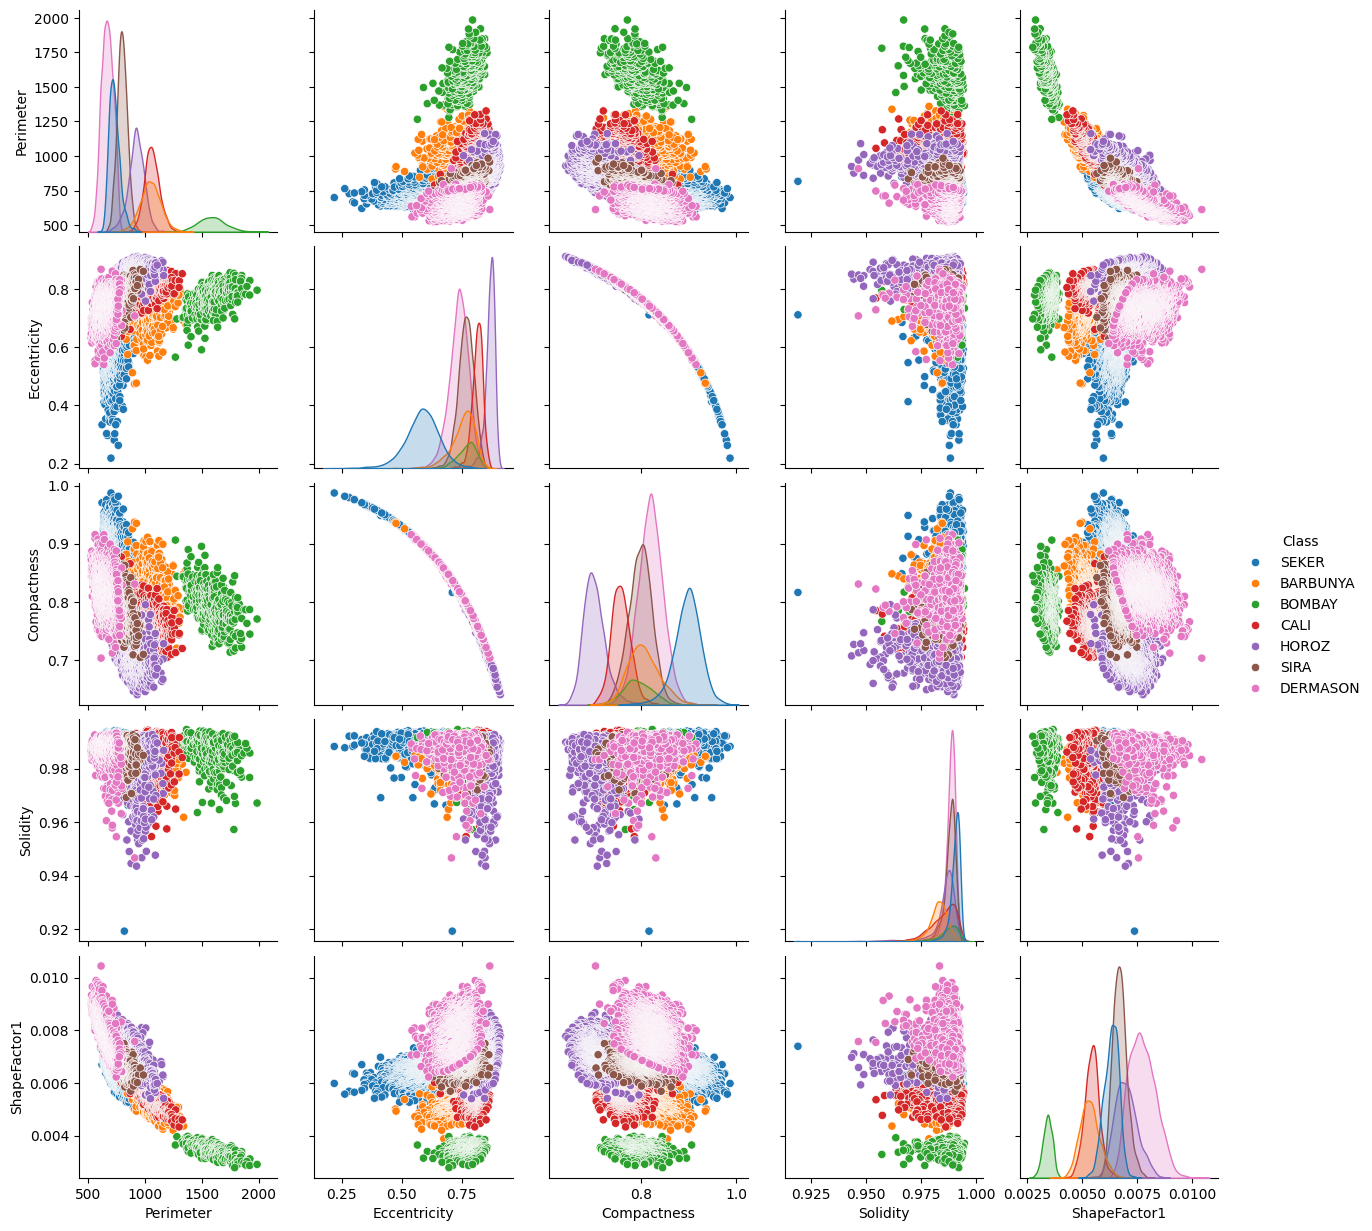

In [ ]:
sns.pairplot(data=df,vars=chosen_feats,hue='Class')
plt.show()

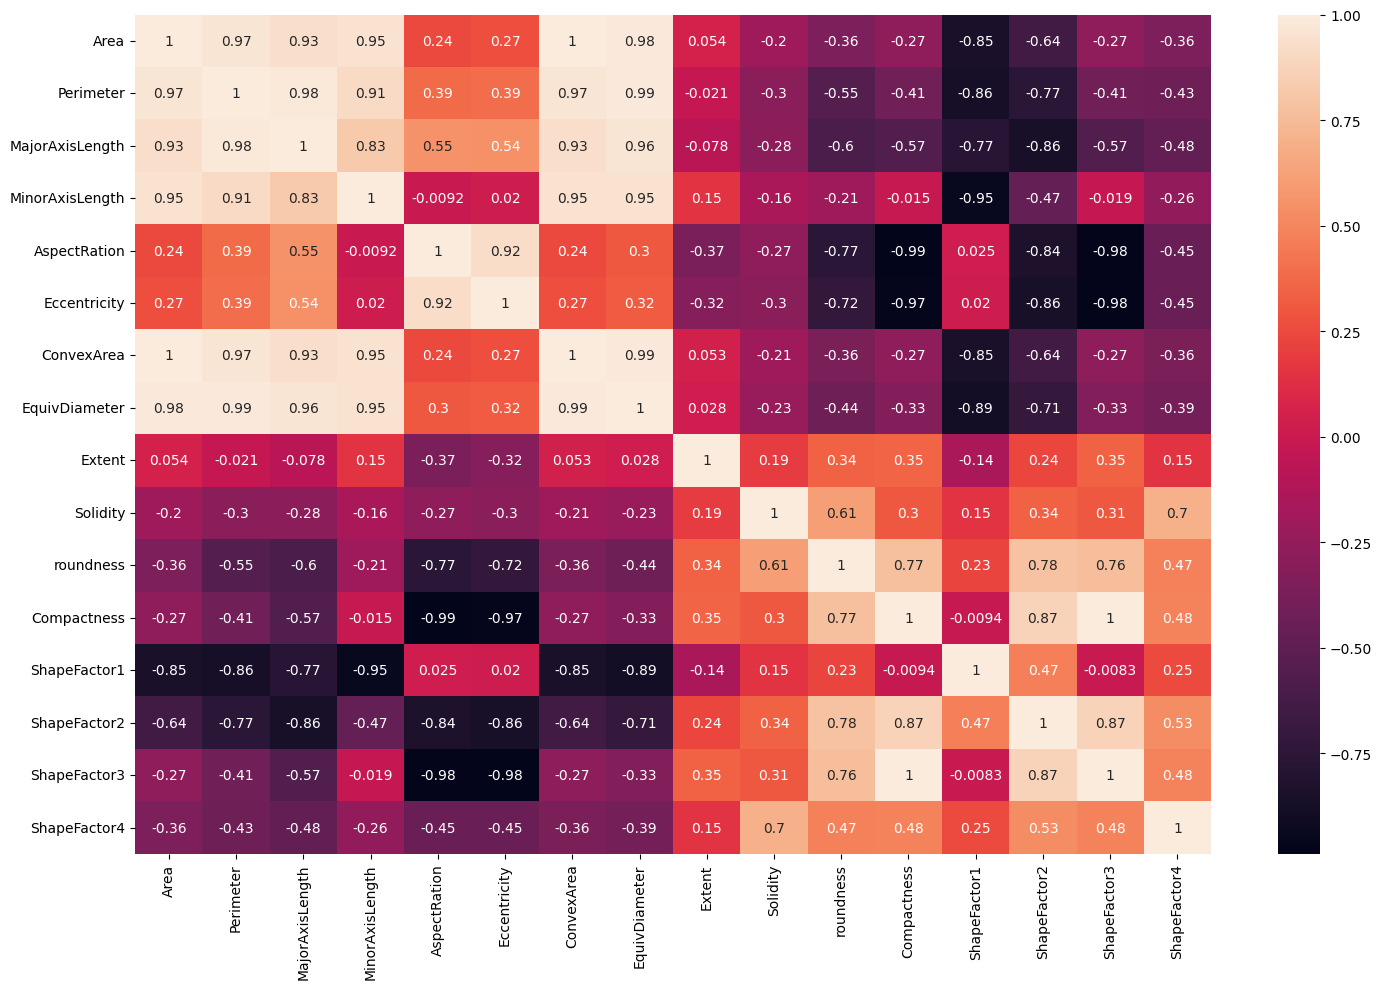

In [ ]:
plt.figure(figsize=(15,10))
sns.heatmap(df.drop(columns='Class').corr() , annot=True )
plt.tight_layout()
plt.show()

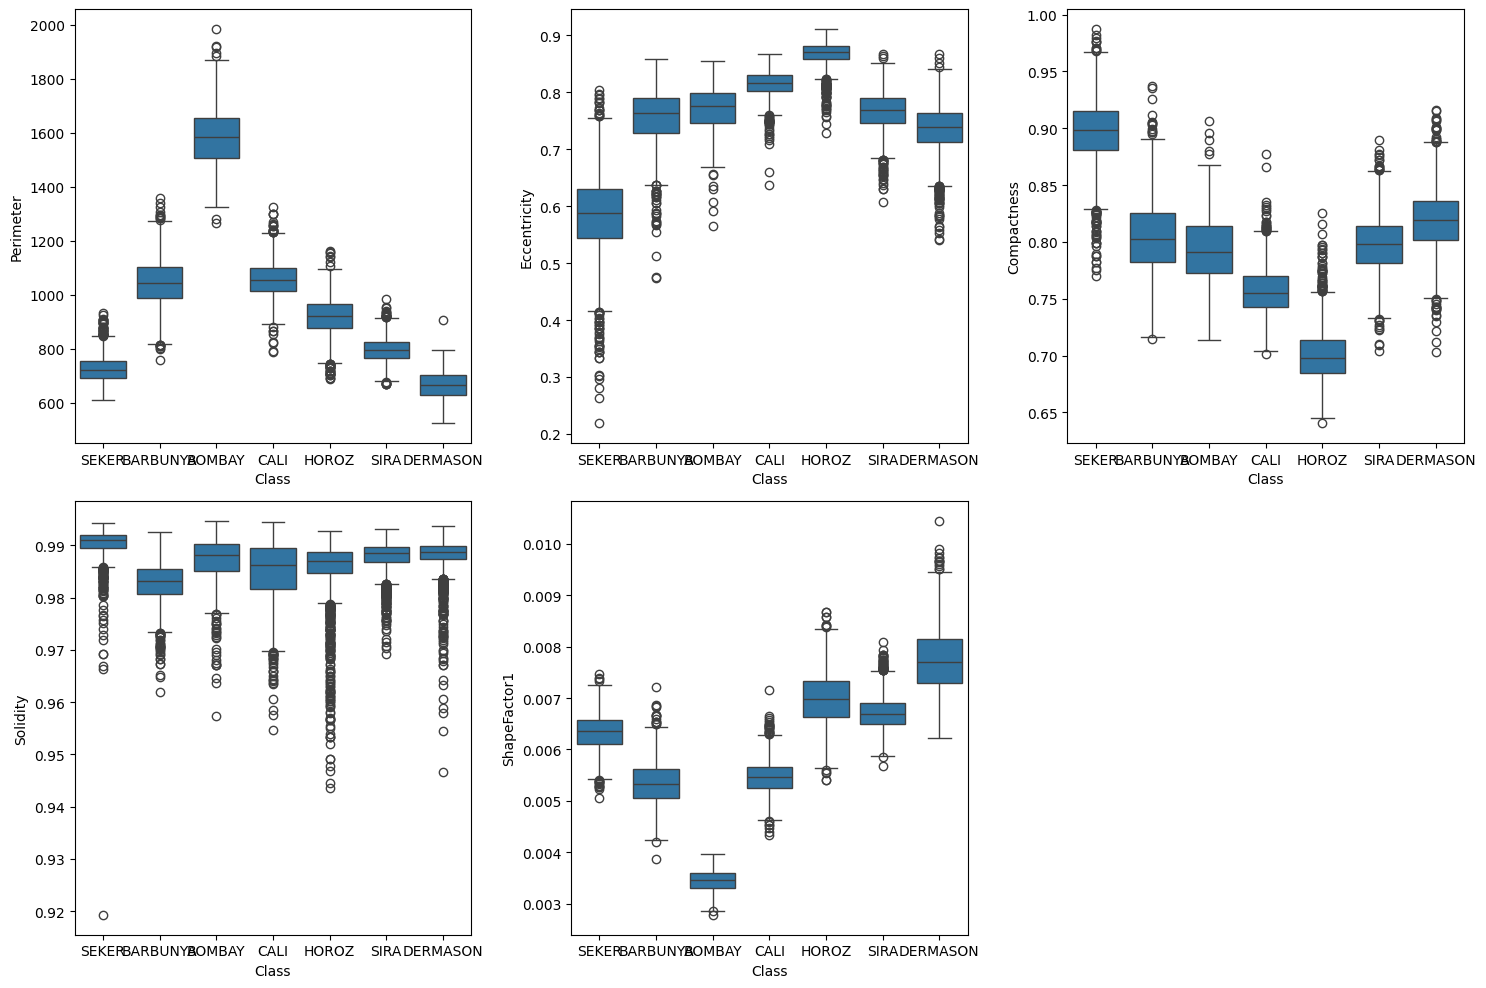

In [ ]:
plt.figure(figsize=(15,10))
for i,col in enumerate(chosen_feats , start=1):
  plt.subplot(2,3,i)
  sns.boxplot(data=df , x="Class" , y=col)
plt.tight_layout()
plt.show()

In [ ]:
"""
1.Class separability:
    from the picked feats pair plots "BOMBAY" class is mostly highly seperated from the other classes, the rest of the classes are overlapping a bit

2.Most separable features:
    from the chosen feats the most separable feats are : Perimeter ,
    and since it has high corr with  "Area" ,  'MajorAxisLength', 'MinorAxisLength', 'ConvexArea' , "EquivDiameter"
    so we can say all those 6 features seperate classes so well

3.Highly correlated/redundant features:
    a) "Area" , 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'ConvexArea' , "EquivDiameter
    b) "Eccentricity" and "AspectRation"
    c) "Compactness" and "ShapeFactor3"
"""

'\n1.Class separability:\n    from the picked feats pair plots "BOMBAY" class is mostly highly seperated from the other classes, the rest of the classes are overlapping a bit\n\n2.Most separable features:\n    from the chosen feats the most separable feats are : Perimeter ,\n    and since it has high corr with  "Area" ,  \'MajorAxisLength\', \'MinorAxisLength\', \'ConvexArea\' , "EquivDiameter"\n    so we can say all those 6 features seperate classes so well\n\n3.Highly correlated/redundant features:\n    a) "Area" , \'Perimeter\', \'MajorAxisLength\', \'MinorAxisLength\', \'ConvexArea\' , "EquivDiameter\n    b) "Eccentricity" and "AspectRation"\n    c) "Compactness" and "ShapeFactor3"\n'

##Data cleaning/preparation

In [ ]:
df.isna().sum()

,0
Area,0
Perimeter,0
MajorAxisLength,0
MinorAxisLength,0
AspectRation,0
Eccentricity,0
ConvexArea,0
EquivDiameter,0
Extent,0
Solidity,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  object 
dtypes: float64(1

In [ ]:
df.duplicated().sum()

np.int64(68)

In [ ]:
df.drop_duplicates(inplace=True)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.shape

(13543, 17)

In [ ]:
df['Class'].value_counts()

,count
Class,
DERMASON,3546
SIRA,2636
SEKER,2027
HOROZ,1860
CALI,1630
BARBUNYA,1322
BOMBAY,522


In [ ]:
from sklearn.preprocessing import LabelEncoder
label = LabelEncoder()
df['Class'] = label.fit_transform(df['Class'])

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 13543 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13543 non-null  int64  
 1   Perimeter        13543 non-null  float64
 2   MajorAxisLength  13543 non-null  float64
 3   MinorAxisLength  13543 non-null  float64
 4   AspectRation     13543 non-null  float64
 5   Eccentricity     13543 non-null  float64
 6   ConvexArea       13543 non-null  int64  
 7   EquivDiameter    13543 non-null  float64
 8   Extent           13543 non-null  float64
 9   Solidity         13543 non-null  float64
 10  roundness        13543 non-null  float64
 11  Compactness      13543 non-null  float64
 12  ShapeFactor1     13543 non-null  float64
 13  ShapeFactor2     13543 non-null  float64
 14  ShapeFactor3     13543 non-null  float64
 15  ShapeFactor4     13543 non-null  float64
 16  Class            13543 non-null  int64  
dtypes: float64(14), i

In [ ]:
df.Class.value_counts()

,count
Class,
3,3546
6,2636
5,2027
4,1860
2,1630
0,1322
1,522


In [ ]:
from sklearn.model_selection import train_test_split
x=df.drop(columns='Class')
y=df['Class']

In [ ]:
#I will use stratify since the class is imbalanced
x_train , x_test , y_train , y_test = train_test_split(x,y,test_size=0.2,stratify=y,random_state=42)

##Decision Tree

In [ ]:
from sklearn.tree import DecisionTreeClassifier
dt_model = DecisionTreeClassifier()
dt_model.fit(x_train,y_train)

DecisionTreeClassifier()

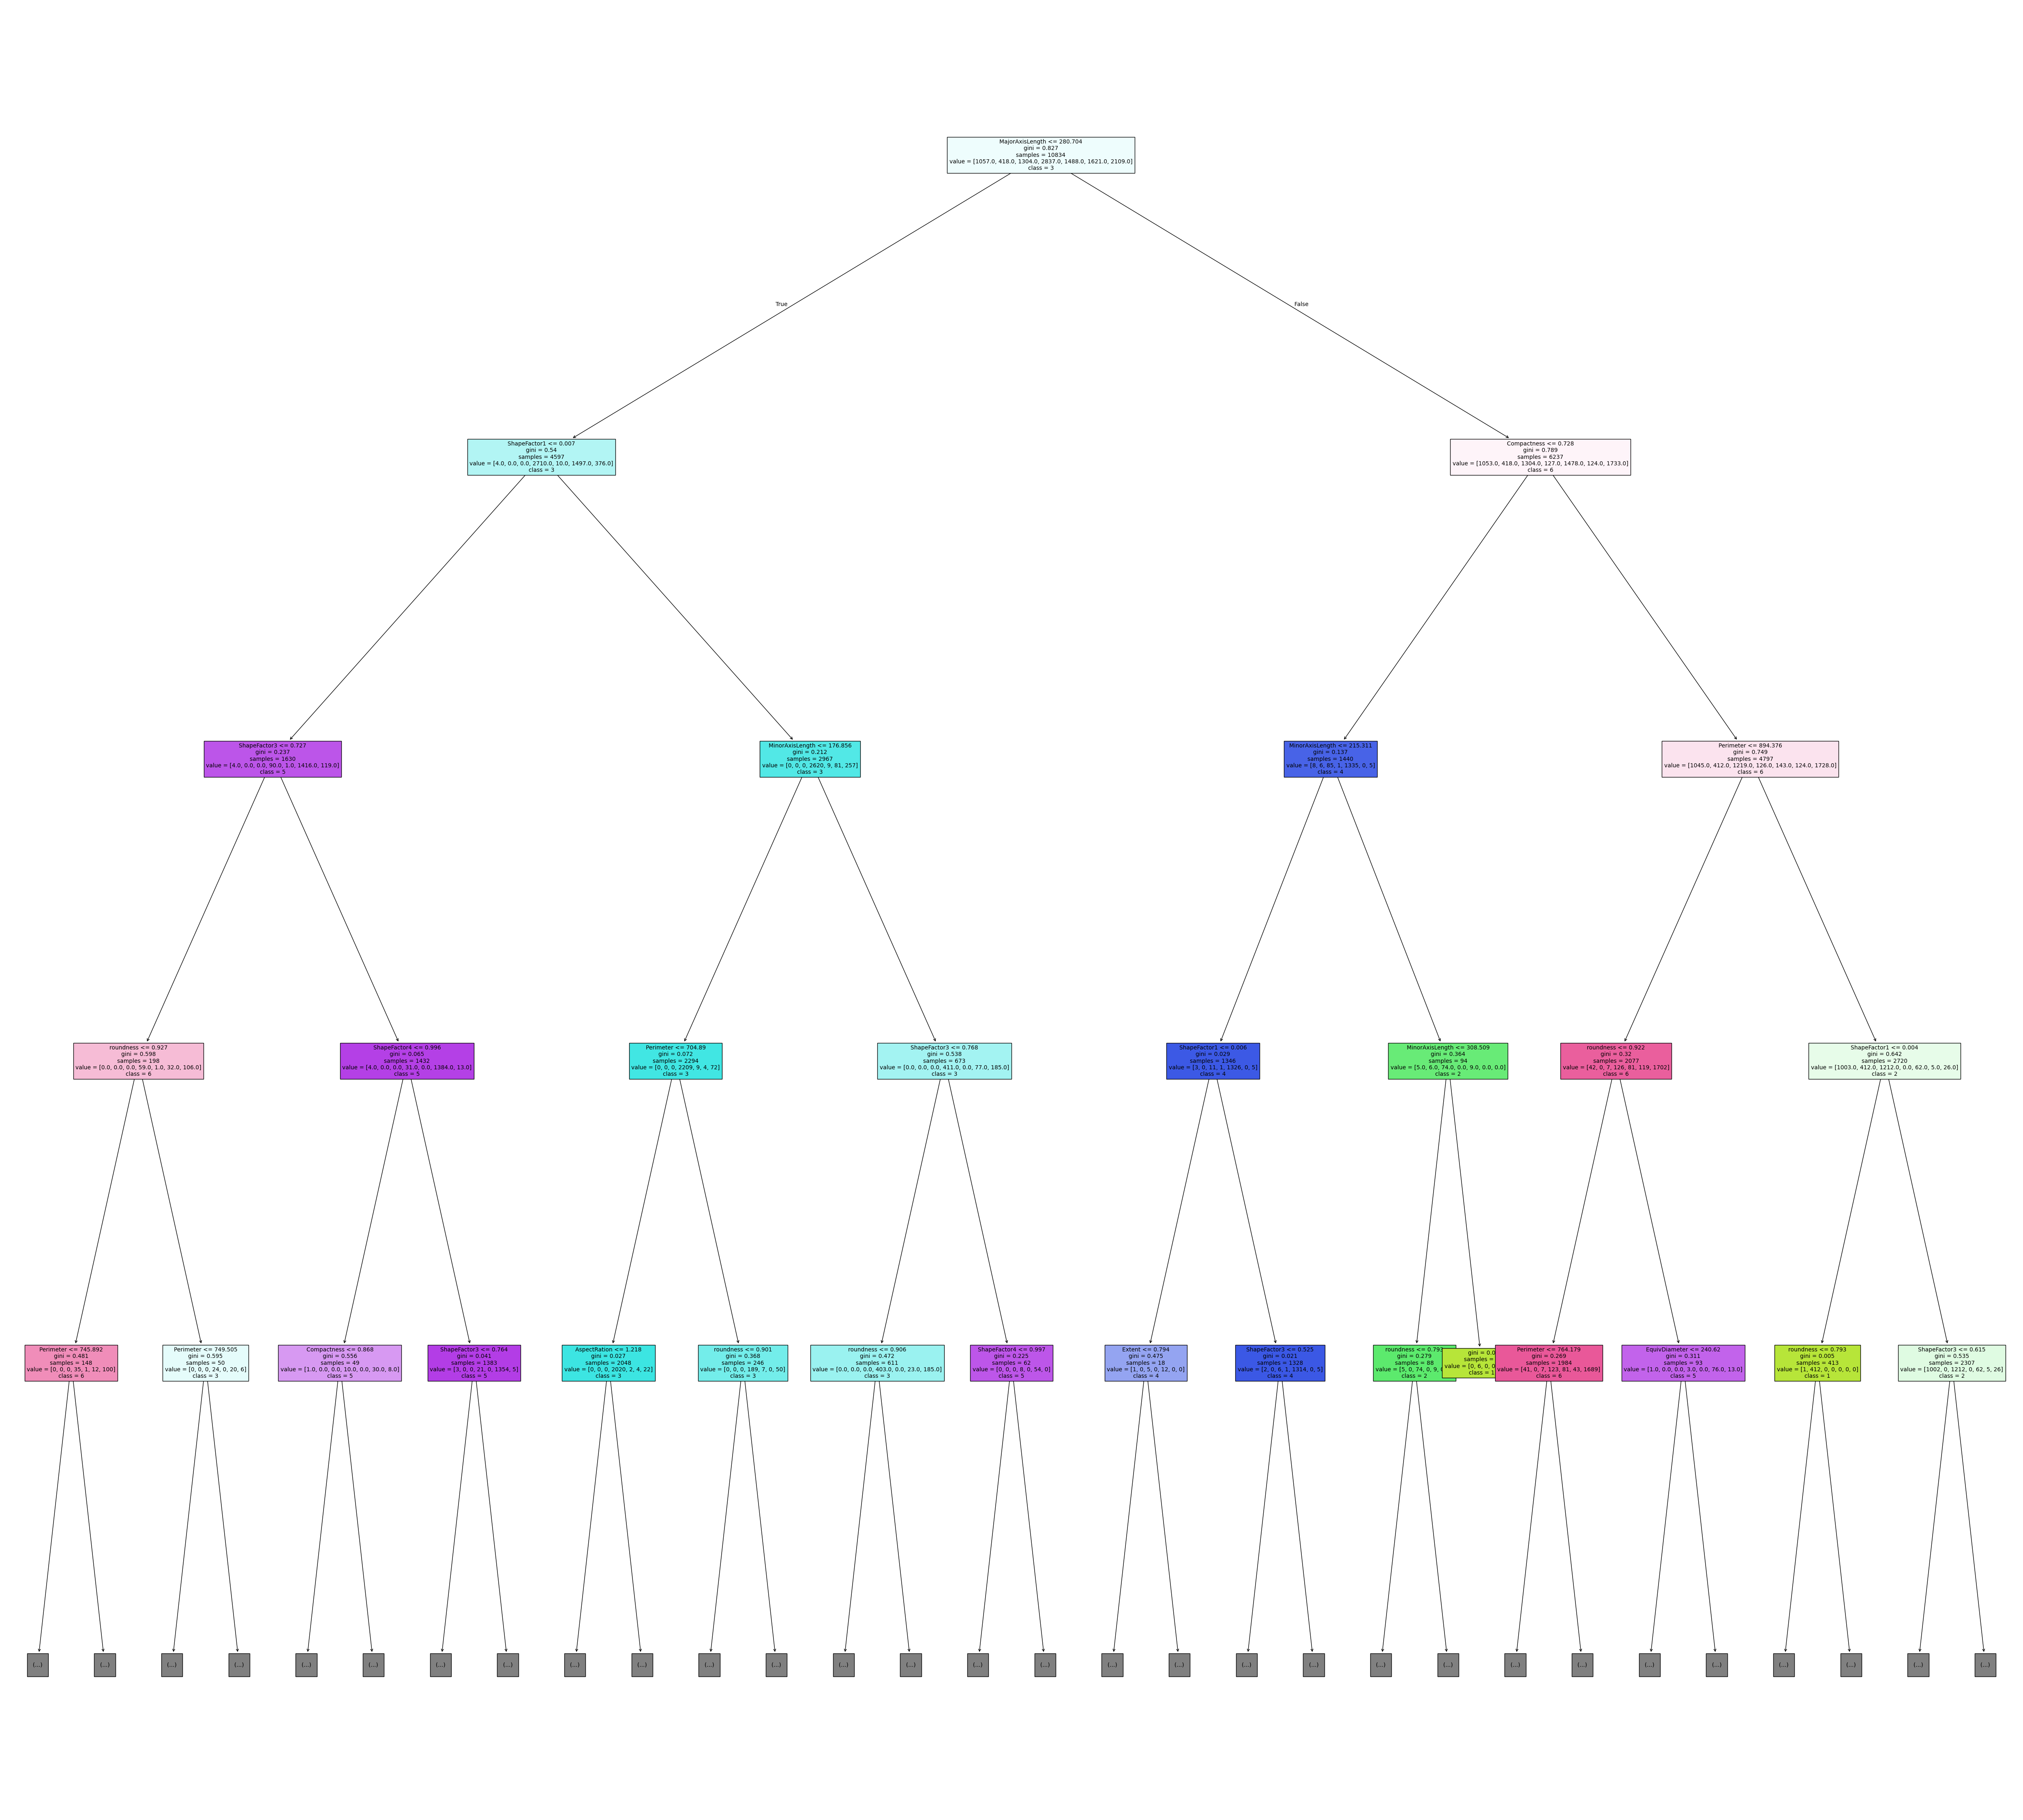

In [ ]:
from sklearn.tree import plot_tree
plt.figure(figsize=(50,45))
plot_tree(dt_model , max_depth=4 , feature_names=x.columns , class_names=dt_model.classes_.astype(str),filled=True,fontsize=10)
plt.tight_layout()
plt.show()

In [ ]:
"""
Analyze the top 3 splitting nodes:  Feature => Threshold => Classes being separated
  1. MajorAxisLngth => 280 => less than then class 3 , greater than another class
  2. Compacness => 0.728 => less than then class 6 , greater than then another class
  3. shapeFactor2 => 0.007 => less than class 3
"""

'\nAnalyze the top 3 splitting nodes:  Feature => Threshold => Classes being separated\n  1. MajorAxisLngth => 280 => less than then class 3 , greater than another class\n  2. Compacness => 0.728 => less than then class 6 , greater than then another class\n  3. shapeFactor2 => 0.007 => less than class 3\n'

In [ ]:
dt_model.score(x_train,y_train)

1.0

In [ ]:
dt_model.score(x_test,y_test)

0.8962716869693614

In [ ]:
# that is overfittinng

In [ ]:
from sklearn.metrics import confusion_matrix
y_pred = dt_model.predict(x_test)

In [ ]:
confusion_matrix(y_test , y_pred)

array([[238,   0,  17,   1,   0,   3,   6],
       [  0, 104,   0,   0,   0,   0,   0],
       [ 16,   0, 299,   0,   7,   1,   3],
       [  0,   0,   0, 635,   3,  12,  59],
       [  3,   0,  10,   4, 346,   0,   9],
       [  6,   0,   0,  10,   0, 380,  10],
       [  4,   0,   4,  62,  10,  21, 426]])

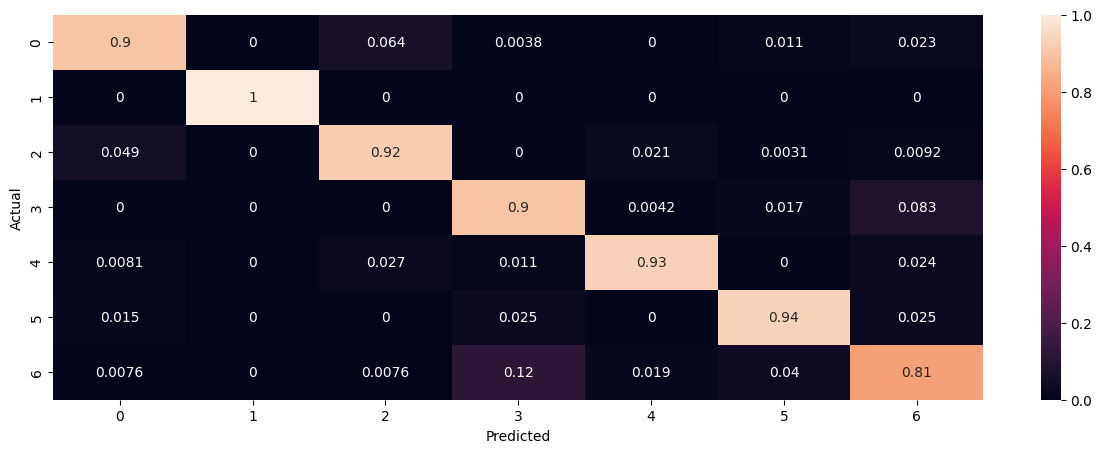

In [ ]:
plt.figure(figsize=(15,5))
sns.heatmap(confusion_matrix(y_test , y_pred , normalize="true") , annot=True , xticklabels=dt_model.classes_ , yticklabels=dt_model.classes_)
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.show()

In [ ]:
"""
class 6 is the most miss classified and accoarding to the value_counts before and after the encoding
class 6 is class SIRA

then class 3
which is DERMASON

then class 0
BARBUNYA

class 1 which is BOMBAY which has the least samples was 100% accurate which is realy odd
"""

'\nclass 6 is the most miss classified and accoarding to the value_counts before and after the encoding\nclass 6 is class SIRA\n\nthen class 3\nwhich is DERMASON\n\nthen class 0\nBARBUNYA\n\nclass 1 which is BOMBAY which has the least samples was 100% accurate which is realy odd\n'

##Improve the Decision Tree

###Splitting criterion

In [ ]:
dt1 = DecisionTreeClassifier(criterion="gini",random_state=42)

In [ ]:
dt1.fit(x_train,y_train)

DecisionTreeClassifier(random_state=42)

In [ ]:
dt1.score(x_train,y_train)

1.0

In [ ]:
dt1.score(x_test,y_test)

0.896640826873385

In [ ]:
dt2 = DecisionTreeClassifier(criterion="entropy",random_state=42)

In [ ]:
dt2.fit(x_train,y_train)

DecisionTreeClassifier(criterion='entropy', random_state=42)

In [ ]:
dt2.score(x_train,y_train)

1.0

In [ ]:
dt2.score(x_test,y_test)

0.8885197489848653

In [ ]:
#lets use gini

In [ ]:
#dt function
def dt(crit="gini",maxD=None,ccp=0.0,random=42):
  return DecisionTreeClassifier(criterion=crit , max_depth=maxD , ccp_alpha=ccp  , random_state=random)

###max_depth

In [ ]:
maxD_values = [5,6,7,8,9]
results = []
for max_D in maxD_values:
  model = dt(maxD=max_D)
  model.fit(x_train,y_train)
  train_accuracy = model.score(x_train,y_train)
  test_accurscy = model.score(x_test,y_test)
  results.append(
      {
          "max depth" : max_D ,
          "train accuracy" : train_accuracy,
          "test accuracy" : test_accurscy
      }
  )

In [ ]:
results

[{'max depth': 5,
  'train accuracy': 0.8908067195864869,
  'test accuracy': 0.8748615725359912},
 {'max depth': 6,
  'train accuracy': 0.9145283367177405,
  'test accuracy': 0.8829826504245109},
 {'max depth': 7,
  'train accuracy': 0.92717371238693,
  'test accuracy': 0.8929494278331488},
 {'max depth': 8,
  'train accuracy': 0.9395421820195681,
  'test accuracy': 0.8951642672572905},
 {'max depth': 9,
  'train accuracy': 0.9541258999446188,
  'test accuracy': 0.9032853451458103}]

In [ ]:
# max_depth = 7 , the accuracy is better and the differrence between the test and the train is not as big as the higher max depths

###Cost-complexity pruning


In [ ]:
ccp_values = [0.00001,0.0001,0.001,0.01,0.1,1]
results1 = []
for alpha in ccp_values:
  model = dt(maxD=7 , ccp=alpha)
  model.fit(x_train,y_train)
  train_accuracy = model.score(x_train,y_train)
  test_accurscy = model.score(x_test,y_test)
  results1.append(
      {
          "ccp alpha" : alpha ,
          "train accuracy" : train_accuracy,
          "test accuracy" : test_accurscy
      }
  )

In [ ]:
results1

[{'ccp alpha': 1e-05,
  'train accuracy': 0.92717371238693,
  'test accuracy': 0.8929494278331488},
 {'ccp alpha': 0.0001,
  'train accuracy': 0.9267122023260107,
  'test accuracy': 0.8929494278331488},
 {'ccp alpha': 0.001,
  'train accuracy': 0.9137899206202695,
  'test accuracy': 0.8911037283130306},
 {'ccp alpha': 0.01,
  'train accuracy': 0.8869300350747646,
  'test accuracy': 0.8778146917681802},
 {'ccp alpha': 0.1,
  'train accuracy': 0.7647221709433266,
  'test accuracy': 0.7593207825765965},
 {'ccp alpha': 1,
  'train accuracy': 0.2618608085656267,
  'test accuracy': 0.2617201919527501}]

In [ ]:
ccp_values = [0.0001,0.0002,0.0003,0.0004,0.0005,0.001,0.002,0.003,0.004,0.005,]
results2 = []
for alpha in ccp_values:
  model = dt(maxD=7 , ccp=alpha)
  model.fit(x_train,y_train)
  train_accuracy = model.score(x_train,y_train)
  test_accurscy = model.score(x_test,y_test)
  results2.append(
      {
          "ccp alpha" : alpha ,
          "train accuracy" : train_accuracy,
          "test accuracy" : test_accurscy
      }
  )

In [ ]:
results2

[{'ccp alpha': 0.0001,
  'train accuracy': 0.9267122023260107,
  'test accuracy': 0.8929494278331488},
 {'ccp alpha': 0.0002,
  'train accuracy': 0.9249584640945172,
  'test accuracy': 0.8940568475452196},
 {'ccp alpha': 0.0003,
  'train accuracy': 0.9232047258630238,
  'test accuracy': 0.8947951273532669},
 {'ccp alpha': 0.0004,
  'train accuracy': 0.9214509876315303,
  'test accuracy': 0.8947951273532669},
 {'ccp alpha': 0.0005,
  'train accuracy': 0.9198818534244046,
  'test accuracy': 0.8947951273532669},
 {'ccp alpha': 0.001,
  'train accuracy': 0.9137899206202695,
  'test accuracy': 0.8911037283130306},
 {'ccp alpha': 0.002,
  'train accuracy': 0.9076979878161344,
  'test accuracy': 0.8911037283130306},
 {'ccp alpha': 0.003,
  'train accuracy': 0.903821303304412,
  'test accuracy': 0.8881506090808416},
 {'ccp alpha': 0.004,
  'train accuracy': 0.9000369208048735,
  'test accuracy': 0.8851974898486527},
 {'ccp alpha': 0.005,
  'train accuracy': 0.9000369208048735,
  'test accuracy

In [ ]:
alpha_values = [item['ccp alpha'] for item in results2]
train_accuracies = [item['train accuracy'] for item in results2]
test_accuracies = [item['test accuracy'] for item in results2]

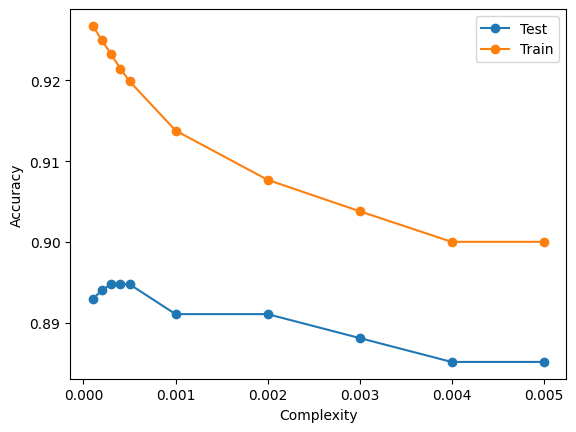

In [ ]:
plt.plot(alpha_values , test_accuracies , marker="o", label="Test")
plt.plot(alpha_values , train_accuracies , marker="o", label="Train")
plt.xlabel("Complexity")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [ ]:
#ccp_alpha = 0.0005 least overfitting while having relatively good accuracy

In [ ]:
splits = ["gini","entropy"]
maxD_values = [5,6,7,8,9]
ccp_values = [0.0001,0.0002,0.0003,0.0004,0.0005,0.001,0.002,0.003,0.004,0.005]

table = {
    "params" :[],
    "train accuracy":[],
    "test accuracy":[],
    "tree depth":[]
}

for split in splits:
  model = dt(crit=split)
  model.fit(x_train,y_train)
  train_accuracy = model.score(x_train  , y_train)
  test_accuracy = model.score(x_test  , y_test)
  tree_depth = model.get_depth()
  table["params"].append(f"criteria = {split}")
  table["train accuracy"].append(train_accuracy)
  table["test accuracy"].append(test_accuracy)
  table["tree depth"].append(tree_depth)

for max_D in maxD_values:
  model = dt(maxD=max_D)
  model.fit(x_train,y_train)
  train_accuracy = model.score(x_train  , y_train)
  test_accuracy = model.score(x_test  , y_test)
  tree_depth = model.get_depth()
  table["params"].append(f"max_depth = {max_D}")
  table["train accuracy"].append(train_accuracy)
  table["test accuracy"].append(test_accuracy)
  table["tree depth"].append(tree_depth)

for alpha in ccp_values:
  model = dt(ccp=alpha)
  model.fit(x_train,y_train)
  train_accuracy = model.score(x_train  , y_train)
  test_accuracy = model.score(x_test  , y_test)
  tree_depth = model.get_depth()
  table["params"].append(f"ccp_value = {alpha}")
  table["train accuracy"].append(train_accuracy)
  table["test accuracy"].append(test_accuracy)
  table["tree depth"].append(tree_depth)

In [ ]:
table = pd.DataFrame(table)
table

,params,train accuracy,test accuracy,tree depth
0,criteria = gini,1.000000,0.896641,27
1,criteria = entropy,1.000000,0.888520,18
2,max_depth = 5,0.890807,0.874862,5
3,max_depth = 6,0.914528,0.882983,6
4,max_depth = 7,0.927174,0.892949,7
5,max_depth = 8,0.939542,0.895164,8
6,max_depth = 9,0.954126,0.903285,9
7,ccp_value = 0.0001,0.989662,0.904024,27
8,ccp_value = 0.0002,0.964741,0.910668,16
9,ccp_value = 0.0003,0.948495,0.907346,13


In [ ]:
"""
pruning improved generalization a bit, very low ccp_alpha decreaced the gab between the train and the test accuracy
and the train accuracy is not 100%
"""

'\npruning improved generalization a bit, very low ccp_alpha decreaced the gab between the train and the test accuracy\nand the train accuracy is not 100%\n'

###GridSearchCV

In [ ]:
from sklearn.model_selection import GridSearchCV
params ={
    "criterion" : ["gini","entropy"],
    "max_depth" : [5,6,7,8,9,10,11,12,13,14,15] ,
    "ccp_alpha" : [0.0001,0.0002,0.0003,0.0004,0.0005,0.001,0.002,0.003,0.004,0.005]
}



In [ ]:
model = DecisionTreeClassifier(random_state=42)
grid_search = GridSearchCV(
    estimator = model ,
    param_grid = params,
    scoring = "f1_macro",
    cv=5
)

In [ ]:
grid_search.fit(x_train,y_train)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(random_state=42),
             param_grid={'ccp_alpha': [0.0001, 0.0002, 0.0003, 0.0004, 0.0005,
                                       0.001, 0.002, 0.003, 0.004, 0.005],
                         'criterion': ['gini', 'entropy'],
                         'max_depth': [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]},
             scoring='f1_macro')

In [ ]:
grid_search.best_params_

{'ccp_alpha': 0.0004, 'criterion': 'gini', 'max_depth': 14}

In [ ]:
grid_search.score(x_train,y_train)

0.9484796447503205

In [ ]:
grid_search.score(x_test,y_test)

0.920958232271078

#Bagging

In [ ]:
dt_model = DecisionTreeClassifier(ccp_alpha=0.0004 , criterion="gini" , max_depth= 14 , random_state=42)